In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/dataset.csv")
print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (5574, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
# Dataset exploration

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nDescriptive Statistics:")
display(df.describe(include="all"))

Dataset Shape:
(5574, 2)

Column Names:
['label', 'text']

Data Types:
label    str
text     str
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   label   5574 non-null   str  
 1   text    5574 non-null   str  
dtypes: str(2)
memory usage: 543.0 KB

Descriptive Statistics:


,label,text
count,5574,5574
unique,2,5171
top,ham,"Sorry, I'll call later"
freq,4827,30


In [ ]:
# Missing values and duplicate analysis

print("Shape before cleaning:", df.shape)

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nRepeated text messages:")
print(df.duplicated(subset=["text"]).sum())

print("\nClass distribution:")
print(df["label"].value_counts())

Shape before cleaning: (5574, 2)

Missing values per column:
label    0
text     0
dtype: int64

Total missing values:
0

Duplicate rows:
403

Repeated text messages:
403

Class distribution:
label
ham     4827
spam     747
Name: count, dtype: int64


In [ ]:
# Preserve the original dataset
df_original = df.copy()

print("Shape before cleaning:", df.shape)

# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after cleaning:", df.shape)
print("Rows removed:", len(df_original) - len(df))

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows after cleaning:")
print(df.duplicated().sum())

print("\nClass distribution after cleaning:")
print(df["label"].value_counts())

Shape before cleaning: (5574, 2)
Shape after cleaning: (5171, 2)
Rows removed: 403

Missing values after cleaning:
label    0
text     0
dtype: int64

Duplicate rows after cleaning:
0

Class distribution after cleaning:
label
ham     4518
spam     653
Name: count, dtype: int64


In [ ]:
# 1. LOC: Select spam messages longer than 100 characters

spam_long = df.loc[
    (df["label"] == "spam") &
    (df["text"].str.len() > 100),
    ["label", "text"]
]

print("Spam messages longer than 100 characters:")
print("Count:", len(spam_long))
display(spam_long.head())


# 2. ILOC: Select the first five rows and both columns

print("\nFirst five rows using iloc:")
display(df.iloc[0:5, 0:2])


# 3. ILOC with np.r_: Select non-consecutive rows

print("\nSelected rows using np.r_:")
selected_rows = np.r_[0:3, 10:13]

display(df.iloc[selected_rows, :])

Spam messages longer than 100 characters:
Count: 580


,label,text
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
5,spam,FreeMsg Hey there darling it's been 3 week's n...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...
11,spam,"SIX chances to win CASH! From 100 to 20,000 po..."



First five rows using iloc:


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Selected rows using np.r_:


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
10,ham,I'm gonna be home soon and i don't want to tal...
11,spam,"SIX chances to win CASH! From 100 to 20,000 po..."
12,spam,URGENT! You have won a 1 week FREE membership ...


In [ ]:
# Transformation 1: Encode spam and ham labels
df["label_encoded"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

# Transformation 2: Count characters
df["char_count"] = df["text"].str.len()

# Transformation 3: Count words
df["word_count"] = df["text"].str.split().str.len()

# Transformation 4: Count unique words
df["unique_word_count"] = df["text"].apply(
    lambda text: len(set(text.lower().split()))
)

# Transformation 5: Categorize messages by length
df["length_category"] = pd.cut(
    df["char_count"],
    bins=[-1, 50, 100, float("inf")],
    labels=["Short", "Medium", "Long"]
)

print("Dataset shape after feature engineering:", df.shape)

display(df.head())

print("\nMessage length categories:")
print(df["length_category"].value_counts())

Dataset shape after feature engineering: (5171, 7)


,label,text,label_encoded,char_count,word_count,unique_word_count,length_category
0,ham,"Go until jurong point, crazy.. Available only ...",0,111,20,20,Long
1,ham,Ok lar... Joking wif u oni...,0,29,6,6,Short
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1,155,28,24,Long
3,ham,U dun say so early hor... U c already then say...,0,49,11,10,Short
4,ham,"Nah I don't think he goes to usf, he lives aro...",0,61,13,12,Medium



Message length categories:
length_category
Short     2179
Long      1577
Medium    1415
Name: count, dtype: int64


In [ ]:
# Sampling Methods

# 1. Simple Random Sampling
random_sample = df.sample(
    n=1000,
    random_state=42
)

# 2. Stratified Sampling
from sklearn.model_selection import train_test_split

stratified_sample, _ = train_test_split(
    df,
    train_size=1000,
    stratify=df["label"],
    random_state=42
)

# 3. Cluster Sampling
# Create groups using the first character of each SMS
df["sampling_cluster"] = (
    df["text"].str[0].str.lower().fillna("unknown")
)

# Randomly select entire clusters until we reach
# or exceed approximately 1000 records
rng = np.random.default_rng(42)
clusters = rng.permutation(
    df["sampling_cluster"].unique()
)

selected_clusters = []
total_records = 0

for cluster in clusters:
    selected_clusters.append(cluster)
    total_records += (
        df["sampling_cluster"] == cluster
    ).sum()

    if total_records >= 1000:
        break

cluster_sample = df[
    df["sampling_cluster"].isin(selected_clusters)
].copy()

# Compare class distributions
comparison = pd.DataFrame({
    "Original": df["label"].value_counts(normalize=True),
    "Random": random_sample["label"].value_counts(normalize=True),
    "Stratified": stratified_sample["label"].value_counts(normalize=True),
    "Cluster": cluster_sample["label"].value_counts(normalize=True)
}).fillna(0) * 100

print("Sample sizes:")
print("Original:", len(df))
print("Random:", len(random_sample))
print("Stratified:", len(stratified_sample))
print("Cluster:", len(cluster_sample))

print("\nClass distribution percentages:")
display(comparison.round(2))

print("\nSelected clusters:", selected_clusters)

Sample sizes:
Original: 5171
Random: 1000
Stratified: 1000
Cluster: 1095

Class distribution percentages:


,Original,Random,Stratified,Cluster
label,,,,
ham,87.37,86.5,87.4,85.84
spam,12.63,13.5,12.6,14.16



Selected clusters: ['"', 'w', '…', 'q', '[', 't', 'e', "'", '8', 'b', 'z', '&', 'c']


Correlation Matrix:


,char_count,word_count,unique_word_count,avg_word_length
char_count,1.00,0.97,0.96,0.08
word_count,0.97,1.00,0.98,-0.07
unique_word_count,0.96,0.98,1.00,-0.06
avg_word_length,0.08,-0.07,-0.06,1.00


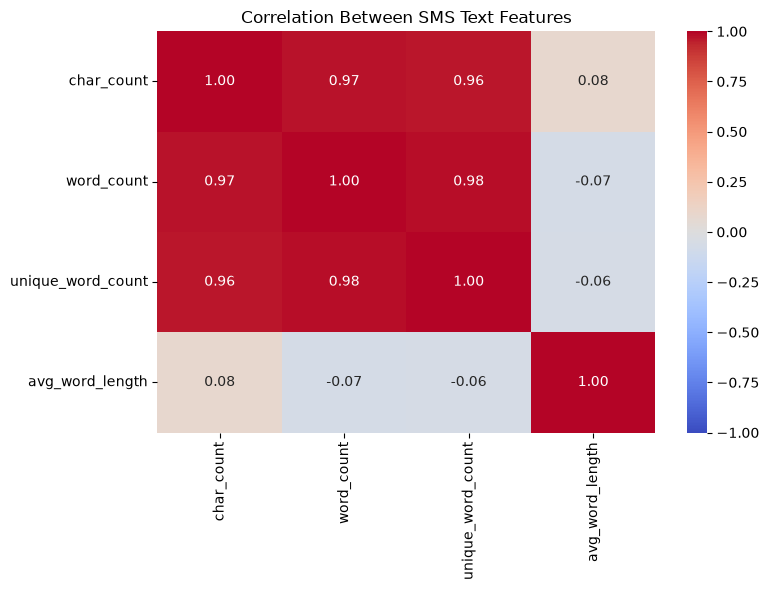

In [ ]:
# Create fourth numerical text feature
df["avg_word_length"] = df["text"].apply(
    lambda text: (
        sum(len(word) for word in text.split()) /
        len(text.split())
        if len(text.split()) > 0 else 0
    )
)

# Select four numerical text features
text_features = [
    "char_count",
    "word_count",
    "unique_word_count",
    "avg_word_length"
]

# Calculate correlation matrix
correlation_matrix = df[text_features].corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

# Create correlation heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between SMS Text Features")
plt.tight_layout()

# Save figure to the mounted output directory
plt.savefig(
    "../output/figures/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import re

# Text cleaning function
def clean_text(text):

    # Handle missing values
    if pd.isna(text):
        return ""

    # Convert to lowercase
    text = str(text).lower()

    # Replace URLs with a placeholder
    text = re.sub(r"https?://\S+|www\.\S+", " url ", text)

    # Replace numbers with a placeholder
    text = re.sub(r"\d+", " num ", text)

    # Remove unnecessary punctuation
    text = re.sub(r"[^\w\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Create a new column (keep original text unchanged)
df["cleaned_text"] = df["text"].apply(clean_text)

# Compare original and cleaned messages
display(df[["label", "text", "cleaned_text"]].head(10))

print("Missing cleaned text values:",
      df["cleaned_text"].isna().sum())

,label,text,cleaned_text
0,ham,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in num a wkly comp to win fa cup fi...
3,ham,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...
5,spam,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darling it s been num week s...
6,ham,Even my brother is not like to speak with me. ...,even my brother is not like to speak with me t...
7,ham,As per your request 'Melle Melle (Oru Minnamin...,as per your request melle melle oru minnaminun...
8,spam,WINNER!! As a valued network customer you have...,winner as a valued network customer you have b...
9,spam,Had your mobile 11 months or more? U R entitle...,had your mobile num months or more u r entitle...


Missing cleaned text values: 0


In [ ]:
from collections import Counter

# Tokenize each cleaned message
df["tokens"] = df["cleaned_text"].apply(
    lambda text: text.split()
)

# Combine all tokens into one list
all_tokens = [
    word
    for tokens in df["tokens"]
    for word in tokens
]

# Calculate statistics
total_tokens = len(all_tokens)
unique_words = len(set(all_tokens))
avg_words = df["tokens"].apply(len).mean()

print("Total tokens:", total_tokens)
print("Unique words:", unique_words)
print("Average words per message:", round(avg_words, 2))

# Show example tokenization
print("\nOriginal message:")
print(df["text"].iloc[2])

print("\nCleaned message:")
print(df["cleaned_text"].iloc[2])

print("\nTokens:")
print(df["tokens"].iloc[2])

Total tokens: 84183
Unique words: 7748
Average words per message: 16.28

Original message:
Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's

Cleaned message:
free entry in num a wkly comp to win fa cup final tkts num st may num text fa to num to receive entry question std txt rate t c s apply num over num s

Tokens:
['free', 'entry', 'in', 'num', 'a', 'wkly', 'comp', 'to', 'win', 'fa', 'cup', 'final', 'tkts', 'num', 'st', 'may', 'num', 'text', 'fa', 'to', 'num', 'to', 'receive', 'entry', 'question', 'std', 'txt', 'rate', 't', 'c', 's', 'apply', 'num', 'over', 'num', 's']


Top 20 Words Before Stop-Word Removal:


,Word,Frequency
0,num,3934
1,i,2860
2,you,2150
3,to,2080
4,a,1325
5,the,1249
6,u,1090
7,and,930
8,in,835
9,is,800



Top 20 Words After Stop-Word Removal:


,Word,Frequency
0,num,3934
1,u,1090
2,s,565
3,t,468
4,m,440
5,just,350
6,ur,322
7,gt,288
8,lt,287
9,ok,261


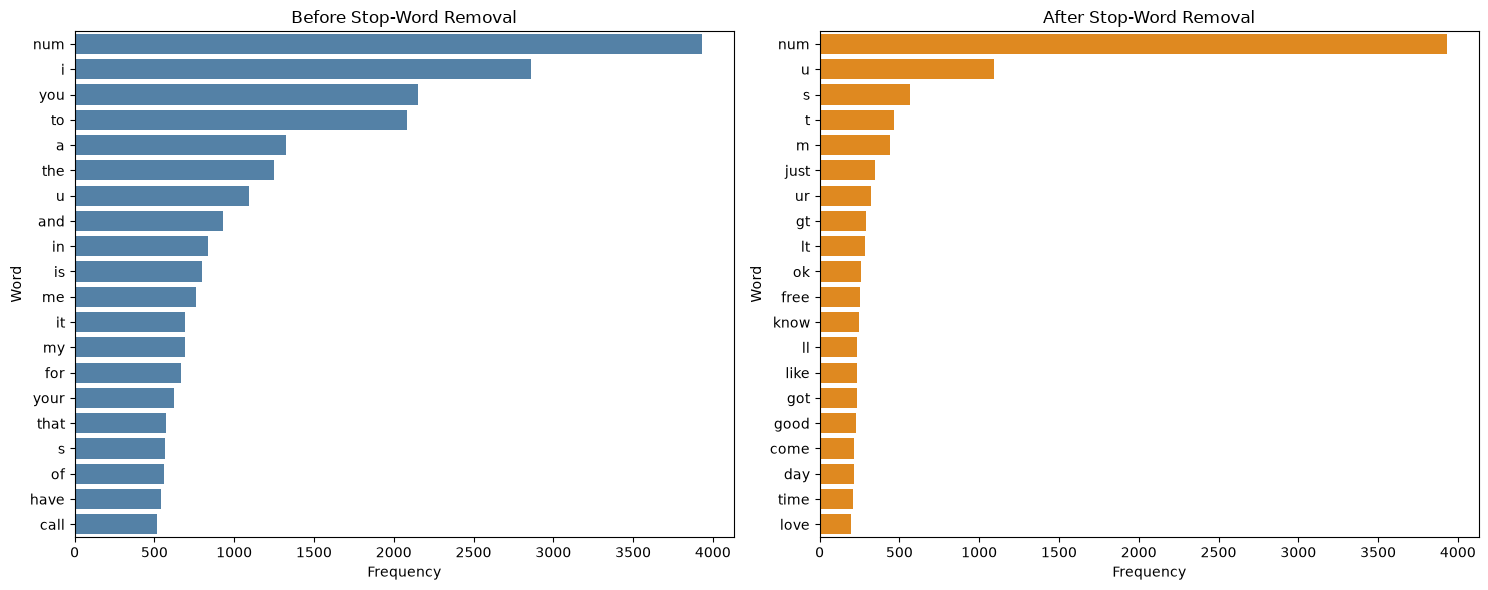

In [ ]:
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Count all words
word_freq = Counter(all_tokens)

# Top 20 words before stop-word removal
top20_before = pd.DataFrame(
    word_freq.most_common(20),
    columns=["Word", "Frequency"]
)

print("Top 20 Words Before Stop-Word Removal:")
display(top20_before)

# Remove English stop words
stop_words = set(ENGLISH_STOP_WORDS)

filtered_tokens = [
    word for word in all_tokens
    if word not in stop_words
]

# Count filtered words
filtered_freq = Counter(filtered_tokens)

top20_after = pd.DataFrame(
    filtered_freq.most_common(20),
    columns=["Word", "Frequency"]
)

print("\nTop 20 Words After Stop-Word Removal:")
display(top20_after)

# Plot comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(
    data=top20_before,
    x="Frequency",
    y="Word",
    ax=axes[0],
    color="steelblue"
)
axes[0].set_title("Before Stop-Word Removal")

sns.barplot(
    data=top20_after,
    x="Frequency",
    y="Word",
    ax=axes[1],
    color="darkorange"
)
axes[1].set_title("After Stop-Word Removal")

plt.tight_layout()

plt.savefig(
    "../output/figures/word_frequency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Spam vs Ham Comparison:


,message_count,avg_char_count,avg_word_count
label,,,
ham,4518,70.89,14.23
spam,653,137.71,23.74



Top 10 words for HAM:


,Word,Frequency
0,num,1131
1,u,938
2,s,481
3,m,397
4,t,388
5,gt,288
6,lt,287
7,just,282
8,ok,256
9,ll,233



Top 10 words for SPAM:


,Word,Frequency
0,num,2803
1,free,197
2,p,158
3,u,152
4,txt,138
5,ur,119
6,stop,116
7,mobile,111
8,text,108
9,claim,96


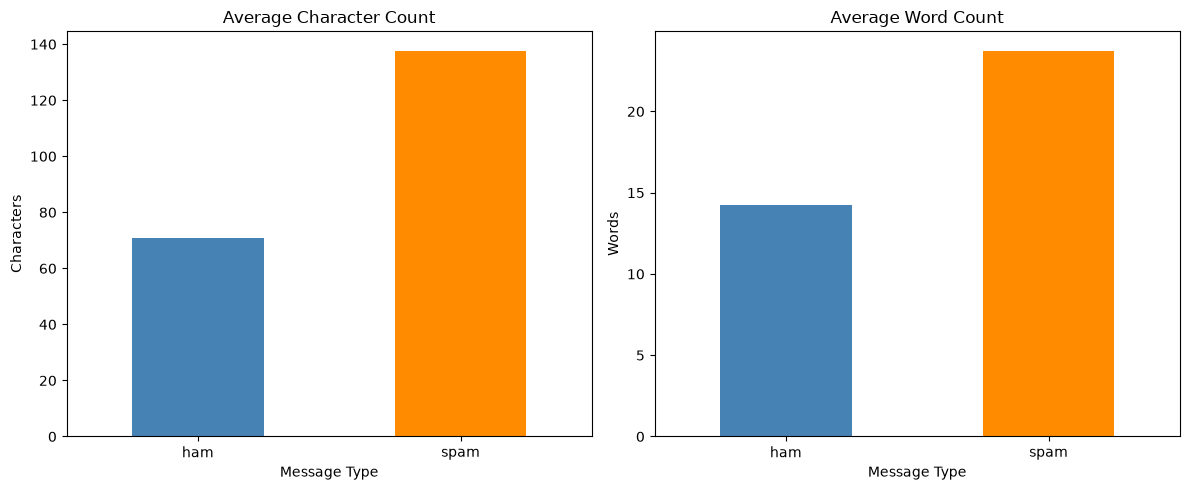

In [ ]:
# Compare spam and ham messages

# Calculate group statistics
group_stats = df.groupby("label").agg(
    message_count=("text", "count"),
    avg_char_count=("char_count", "mean"),
    avg_word_count=("word_count", "mean")
).round(2)

print("Spam vs Ham Comparison:")
display(group_stats)

# Calculate top 10 words for each group
top_words_by_group = {}

for label in ["ham", "spam"]:

    group_tokens = [
        word
        for tokens in df.loc[df["label"] == label, "tokens"]
        for word in tokens
        if word not in stop_words
    ]

    top_words = Counter(group_tokens).most_common(10)
    top_words_by_group[label] = top_words

    print(f"\nTop 10 words for {label.upper()}:")
    display(pd.DataFrame(
        top_words,
        columns=["Word", "Frequency"]
    ))

# Visualize differences
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

group_stats["avg_char_count"].plot(
    kind="bar",
    ax=axes[0],
    color=["steelblue", "darkorange"]
)
axes[0].set_title("Average Character Count")
axes[0].set_xlabel("Message Type")
axes[0].set_ylabel("Characters")
axes[0].tick_params(axis="x", rotation=0)

group_stats["avg_word_count"].plot(
    kind="bar",
    ax=axes[1],
    color=["steelblue", "darkorange"]
)
axes[1].set_title("Average Word Count")
axes[1].set_xlabel("Message Type")
axes[1].set_ylabel("Words")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()

plt.savefig(
    "../output/figures/group_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Five evidence-based insights

ham = group_stats.loc["ham"]
spam = group_stats.loc["spam"]

spam_percentage = (
    df["label"].eq("spam").mean() * 100
)

length_ratio = (
    spam["avg_char_count"] / ham["avg_char_count"]
)

print("INSIGHT 1: CLASS IMBALANCE")
print(
    f"Observation: Spam represents {spam_percentage:.2f}% "
    "of the cleaned dataset."
)
print(
    "Interpretation: The minority spam class requires "
    "careful evaluation using precision, recall and F1-score."
)

print("\nINSIGHT 2: MESSAGE LENGTH")
print(
    f"Observation: Spam messages average "
    f"{spam['avg_char_count']:.2f} characters, "
    f"compared with {ham['avg_char_count']:.2f} for ham."
)
print(
    f"Interpretation: Spam messages are approximately "
    f"{length_ratio:.2f} times as long as ham messages."
)

print("\nINSIGHT 3: WORD COUNT")
print(
    f"Observation: Spam averages {spam['avg_word_count']:.2f} "
    f"words, compared with {ham['avg_word_count']:.2f} for ham."
)
print(
    "Interpretation: Spam messages tend to contain "
    "more textual information."
)

print("\nINSIGHT 4: MOST FREQUENT WORDS")
for label in ["ham", "spam"]:
    words = [word for word, count in top_words_by_group[label][:5]]
    print(f"{label.upper()} top words:", ", ".join(words))

print(
    "Interpretation: Comparing common words helps reveal "
    "differences in language used by each group."
)

print("\nINSIGHT 5: CORRELATION")
corr = correlation_matrix.loc["char_count", "word_count"]

print(
    f"Observation: Character count and word count have "
    f"a correlation of {corr:.2f}."
)
print(
    "Interpretation: Longer messages generally contain "
    "more words, but correlation does not prove causation."
)

INSIGHT 1: CLASS IMBALANCE
Observation: Spam represents 12.63% of the cleaned dataset.
Interpretation: The minority spam class requires careful evaluation using precision, recall and F1-score.

INSIGHT 2: MESSAGE LENGTH
Observation: Spam messages average 137.71 characters, compared with 70.89 for ham.
Interpretation: Spam messages are approximately 1.94 times as long as ham messages.

INSIGHT 3: WORD COUNT
Observation: Spam averages 23.74 words, compared with 14.23 for ham.
Interpretation: Spam messages tend to contain more textual information.

INSIGHT 4: MOST FREQUENT WORDS
HAM top words: num, u, s, m, t
SPAM top words: num, free, p, u, txt
Interpretation: Comparing common words helps reveal differences in language used by each group.

INSIGHT 5: CORRELATION
Observation: Character count and word count have a correlation of 0.97.
Interpretation: Longer messages generally contain more words, but correlation does not prove causation.


In [ ]:
from sklearn.model_selection import train_test_split

# Input: cleaned SMS messages
X = df["cleaned_text"]

# Target: ham (0) or spam (1)
y = df["label_encoded"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Total messages:", len(df))
print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Total messages: 5171
Training messages: 4136
Testing messages: 1035

Training class distribution:
label_encoded
0    3614
1     522
Name: count, dtype: int64

Testing class distribution:
label_encoded
0    904
1    131
Name: count, dtype: int64


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 1)
)

# Learn vocabulary from training data only
X_train_tfidf = tfidf.fit_transform(X_train)

# Apply the same vocabulary to testing data
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

print("\nVocabulary size:", len(tfidf.get_feature_names_out()))

print("\nFirst 20 vocabulary terms:")
print(tfidf.get_feature_names_out()[:20])

Training TF-IDF shape: (4136, 5000)
Testing TF-IDF shape: (1035, 5000)

Vocabulary size: 5000

First 20 vocabulary terms:
['aa' 'aah' 'abi' 'abiola' 'able' 'about' 'abt' 'aburo' 'ac' 'acc'
 'accept' 'access' 'accident' 'accordingly' 'account' 'ache' 'acl'
 'across' 'acting' 'action']


In [ ]:
from sklearn.naive_bayes import MultinomialNB

# Create the classifier
nb_model = MultinomialNB(alpha=1.0)

# Train using TF-IDF features and known labels
nb_model.fit(X_train_tfidf, y_train)

# Predict labels for unseen test messages
y_pred = nb_model.predict(X_test_tfidf)

print("Model trained successfully!")

print("\nFirst 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 actual labels:")
print(y_test.iloc[:10].to_numpy())

Model trained successfully!

First 10 predictions:
[0 0 0 0 1 0 0 1 0 0]

First 10 actual labels:
[0 0 0 0 1 0 0 1 0 0]


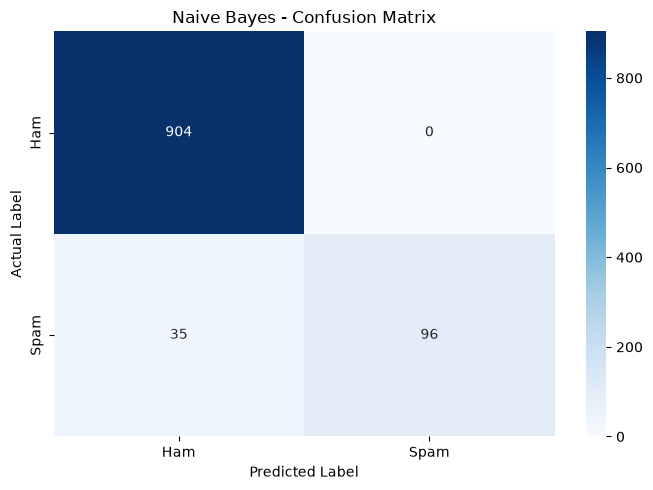

In [ ]:
from sklearn.metrics import confusion_matrix
# Create confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()

plt.savefig(
    "../output/figures/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.preprocessing import Normalizer

# Convert all cleaned messages into TF-IDF features
# For unsupervised exploratory clustering
X_all_tfidf = tfidf.transform(df["cleaned_text"])

# Reduce dimensionality for faster clustering
svd = TruncatedSVD(n_components=50, random_state=42)

X_reduced = svd.fit_transform(X_all_tfidf)

# Normalize reduced vectors
normalizer = Normalizer()
X_cluster = normalizer.fit_transform(X_reduced)

# Choose 2 clusters as an initial experiment
# because our dataset contains two known classes
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

df["cluster"] = kmeans.fit_predict(X_cluster)

print("Clustering completed successfully!")

print("\nReduced data shape:")
print(X_cluster.shape)

print("\nCluster sizes:")
print(df["cluster"].value_counts().sort_index())

print("\nKnown labels vs discovered clusters:")
display(pd.crosstab(df["cluster"], df["label"]))

Clustering completed successfully!

Reduced data shape:
(5171, 50)

Cluster sizes:
cluster
0    4265
1     906
Name: count, dtype: int64

Known labels vs discovered clusters:


label,ham,spam
cluster,,
0,4183,82
1,335,571


In [ ]:
from sklearn.metrics import silhouette_score
import numpy as np

# Calculate silhouette score on a reproducible sample
silhouette = silhouette_score(
    X_cluster,
    df["cluster"],
    metric="euclidean",
    sample_size=1000,
    random_state=42
)

print(f"Silhouette Score: {silhouette:.4f}")

print("\nCluster sizes:")
print(df["cluster"].value_counts().sort_index())

print("\nCluster vs Known Labels:")
display(pd.crosstab(df["cluster"], df["label"]))

Silhouette Score: 0.0647

Cluster sizes:
cluster
0    4265
1     906
Name: count, dtype: int64

Cluster vs Known Labels:


label,ham,spam
cluster,,
0,4183,82
1,335,571


In [ ]:
# Identify representative terms for each cluster

feature_names = tfidf.get_feature_names_out()

cluster_top_terms = {}

for cluster_id in sorted(df["cluster"].unique()):

    # Select messages belonging to this cluster
    mask = df["cluster"].to_numpy() == cluster_id

    # Calculate average TF-IDF weights
    avg_tfidf = np.asarray(
        X_all_tfidf[mask].mean(axis=0)
    ).ravel()

    # Select the 10 highest-weighted terms
    top_indices = np.argsort(avg_tfidf)[-10:][::-1]

    top_terms = feature_names[top_indices].tolist()

    cluster_top_terms[cluster_id] = top_terms

    print(f"\nCLUSTER {cluster_id}")
    
    print("Number of messages:", mask.sum())
    print("Top 10 terms:", ", ".join(top_terms))

    print("\nLabel distribution:")
    print(
        df.loc[mask, "label"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )


CLUSTER 0
Number of messages: 4265
Top 10 terms: you, to, the, in, me, and, it, my, is, that

Label distribution:
label
ham     98.08
spam     1.92
Name: proportion, dtype: float64

CLUSTER 1
Number of messages: 906
Top 10 terms: num, to, call, free, your, or, now, txt, you, ur

Label distribution:
label
spam    63.02
ham     36.98
Name: proportion, dtype: float64


In [ ]:
from pathlib import Path

# Prepare output directory
output_dir = Path("../output")
output_dir.mkdir(parents=True, exist_ok=True)

# Save cleaned dataset
df_export = df.drop(columns=["tokens", "sampling_cluster"],
                    errors="ignore")

df_export.to_csv(
    output_dir / "cleaned_data.csv",
    index=False
)

# Prepare clustering report
cluster_sizes = df["cluster"].value_counts().sort_index()
cluster_labels = pd.crosstab(df["cluster"], df["label"])

report_lines = [
    "K-MEANS CLUSTERING SUMMARY",
    "==========================",
    "",
    "Dataset: SMS Spam Collection",
    f"Number of messages: {len(df)}",
    "Method: TF-IDF + TruncatedSVD (50 dimensions) + Normalizer + K-Means",
    "Number of clusters (k): 2",
    "Reason for k: Initial experiment based on two known message classes.",
    f"Silhouette Score (1000 sampled records): {silhouette:.4f}",
    "",
    "CLUSTER SIZES",
    cluster_sizes.to_string(),
    "",
    "CLUSTER VS KNOWN LABELS",
    cluster_labels.to_string(),
    ""
]

for cluster_id in sorted(cluster_top_terms):
    report_lines.extend([
        f"CLUSTER {cluster_id}",
        f"Top terms: {', '.join(cluster_top_terms[cluster_id])}",
        ""
    ])

report_lines.extend([
    "INTERPRETATION",
    "Cluster 0: Predominantly ham messages, with common conversational terms.",
    "Cluster 1: Spam-majority group, with promotional and action-oriented terms.",
    "",
    "QUALITY AND LIMITATIONS",
    "The low silhouette score suggests substantial geometric overlap.",
    "Clusters are unsupervised groups, not predicted class labels.",
    "Some top terms are stop words or preprocessing placeholders.",
    "k=2 is an initial choice; comparison with other k values is recommended."
])

cluster_report = "\n".join(report_lines)

(output_dir / "cluster_summary.txt").write_text(
    cluster_report,
    encoding="utf-8"
)

print("Files saved successfully!")
print("1. cleaned_data.csv")
print("2. cluster_summary.txt")
print("\nReport preview:")
print(cluster_report)

Files saved successfully!
1. cleaned_data.csv
2. cluster_summary.txt

Report preview:
K-MEANS CLUSTERING SUMMARY

Dataset: SMS Spam Collection
Number of messages: 5171
Method: TF-IDF + TruncatedSVD (50 dimensions) + Normalizer + K-Means
Number of clusters (k): 2
Reason for k: Initial experiment based on two known message classes.
Silhouette Score (1000 sampled records): 0.0647

CLUSTER SIZES
cluster
0    4265
1     906

CLUSTER VS KNOWN LABELS
label     ham  spam
cluster            
0        4183    82
1         335   571

CLUSTER 0
Top terms: you, to, the, in, me, and, it, my, is, that

CLUSTER 1
Top terms: num, to, call, free, your, or, now, txt, you, ur

INTERPRETATION
Cluster 0: Predominantly ham messages, with common conversational terms.
Cluster 1: Spam-majority group, with promotional and action-oriented terms.

QUALITY AND LIMITATIONS
The low silhouette score suggests substantial geometric overlap.
Clusters are unsupervised groups, not predicted class labels.
Some top terms are

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from pathlib import Path

# Calculate model metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

report = classification_report(
    y_test, y_pred,
    target_names=["Ham", "Spam"],
    zero_division=0
)

cm = confusion_matrix(y_test, y_pred)

# Save results
output_dir = Path("../output")
output_dir.mkdir(parents=True, exist_ok=True)

metrics = f"""
SMS SPAM CLASSIFICATION - MODEL RESULTS
=======================================
Model: Multinomial Naive Bayes
Features: TF-IDF
Training size: {len(X_train)}
Testing size: {len(X_test)}

Accuracy:  {accuracy:.4f}
Precision: {precision:.4f}
Recall:    {recall:.4f}
F1-score:  {f1:.4f}

CLASSIFICATION REPORT
{report}

CONFUSION MATRIX
{cm}
"""

(output_dir / "model_metrics.txt").write_text(
    metrics, encoding="utf-8"
)

print(metrics)
print("model_metrics.txt saved successfully!")

In [ ]:
import os
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Identify the positive class (Spam)
labels = set(y_train)

if 1 in labels:
    spam_label = 1
elif "spam" in [str(label).lower() for label in labels]:
    spam_label = next(
        label for label in labels
        if str(label).lower() == "spam"
    )
else:
    raise ValueError(
        "Could not identify the Spam label. "
        "Check how your target labels are encoded."
    )

# Define two classifiers
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Multinomial Naive Bayes": MultinomialNB()
}

results = []

# Train and evaluate both models using the same data
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)

    predictions = model.predict(X_test_tfidf)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions,
            pos_label=spam_label,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions,
            pos_label=spam_label,
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions,
            pos_label=spam_label,
            zero_division=0
        )
    })

# Display comparison
results_df = pd.DataFrame(results)

print("Supervised Classifier Comparison")
print(results_df.round(4).to_string(index=False))

# Save comparison results
os.makedirs("../output", exist_ok=True)
results_df.to_csv("../output/model_comparison.csv", index=False)

print("\nResults saved to output/model_comparison.csv")

# Identify the best model by F1 score
best_model = results_df.loc[results_df["F1 Score"].idxmax()]

print(
    f"\nBest model by F1 Score: {best_model['Model']} "
    f"({best_model['F1 Score']:.4f})"
)